In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np

In [3]:
import requests
from bs4 import BeautifulSoup

url = "https://www.eazydiner.com/bengaluru/restaurants"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers, timeout=20)

print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

Status code: 200
<title data-next-head="">Checkout Best Restaurants in Bengaluru | Get Upto 50% Off</title>


In [4]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

print("Page title:", soup.title.get_text(strip=True))

print("Restaurant links:")

for link in soup.find_all("a", href=True):
    href = link["href"]
    name = link.get_text(strip=True)

    if "/bengaluru/" in href and name:
        print(name, href)

Page title: Checkout Best Restaurants in Bengaluru | Get Upto 50% Off
Restaurant links:
|View All(23) Outlets /bengaluru/restaurants/sreeraj-lassi-bar
2 https://www.eazydiner.com/bengaluru/restaurants?page=2
3 https://www.eazydiner.com/bengaluru/restaurants?page=3
4 https://www.eazydiner.com/bengaluru/restaurants?page=4
5 https://www.eazydiner.com/bengaluru/restaurants?page=5
6 https://www.eazydiner.com/bengaluru/restaurants?page=6
7 https://www.eazydiner.com/bengaluru/restaurants?page=7
8 https://www.eazydiner.com/bengaluru/restaurants?page=8
221 https://www.eazydiner.com/bengaluru/restaurants?page=221
Next » https://www.eazydiner.com/bengaluru/restaurants?page=2
Tyd Kitchen + BarHennur, North Bengaluru https://www.eazydiner.com/bengaluru/tyd-kitchen-bar-hennur-north-bengaluru-690927
BLR Brewing Co.Yelahanka, North Bengaluru https://www.eazydiner.com/bengaluru/blr-brewing-co-yelahanka-north-bengaluru-718682
Rasah Park Inn & Suites by RadissonPark Inn & Suites by Radisson Bengaluru Yel

In [5]:
restaurant_data = []

for link in soup.find_all("a", href=True):
    href = link["href"]
    name = link.get_text(" ", strip=True)

    if "/bengaluru/" in href and name:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if "restaurants?page=" not in href:
            restaurant_data.append({
                "Restaurant_Name": name,
                "Restaurant_URL": href
            })

# Remove duplicate URLs
unique_restaurants = {
    item["Restaurant_URL"]: item
    for item in restaurant_data
}

restaurant_data = list(unique_restaurants.values())

print("Total restaurants:", len(restaurant_data))

for item in restaurant_data[:10]:
    print(item)

Total restaurants: 23
{'Restaurant_Name': '| View All(23) Outlets', 'Restaurant_URL': 'https://www.eazydiner.com/bengaluru/restaurants/sreeraj-lassi-bar'}
{'Restaurant_Name': 'Tyd Kitchen + Bar Hennur, North Bengaluru', 'Restaurant_URL': 'https://www.eazydiner.com/bengaluru/tyd-kitchen-bar-hennur-north-bengaluru-690927'}
{'Restaurant_Name': 'BLR Brewing Co. Yelahanka, North Bengaluru', 'Restaurant_URL': 'https://www.eazydiner.com/bengaluru/blr-brewing-co-yelahanka-north-bengaluru-718682'}
{'Restaurant_Name': 'Rasah Park Inn & Suites by Radisson Park Inn & Suites by Radisson Bengaluru Yelahanka', 'Restaurant_URL': 'https://www.eazydiner.com/bengaluru/rasah-park-inn-suites-by-radisson-park-inn-suites-by-radisson-bengaluru-yelahanka-702710'}
{'Restaurant_Name': 'Roast Your Beans Ramada by Wyndham Bengaluru Yelahanka', 'Restaurant_URL': 'https://www.eazydiner.com/bengaluru/roast-your-beans-ramada-by-wyndham-bengaluru-yelahanka-668379'}
{'Restaurant_Name': 'RYB - Lobby Lounge Ramada by Wynd

In [6]:
import pandas as pd

restaurant_df = pd.DataFrame(restaurant_data)

display(restaurant_df.head(10))

,Restaurant_Name,Restaurant_URL
0,| View All(23) Outlets,https://www.eazydiner.com/bengaluru/restaurant...
1,"Tyd Kitchen + Bar Hennur, North Bengaluru",https://www.eazydiner.com/bengaluru/tyd-kitche...
2,"BLR Brewing Co. Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/blr-brewin...
3,Rasah Park Inn & Suites by Radisson Park Inn &...,https://www.eazydiner.com/bengaluru/rasah-park...
4,Roast Your Beans Ramada by Wyndham Bengaluru Y...,https://www.eazydiner.com/bengaluru/roast-your...
5,RYB - Lobby Lounge Ramada by Wyndham Bengaluru...,https://www.eazydiner.com/bengaluru/ryb-lobby-...
6,B 64 Ramada by Wyndham Bengaluru Yelahanka,https://www.eazydiner.com/bengaluru/b-64-ramad...
7,"Cafe Green bean Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/cafe-green...
8,"Lake City Restro Avalahalli, Bengaluru",https://www.eazydiner.com/bengaluru/lake-city-...
9,"Grasa Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/grasa-yela...


In [7]:
import requests
import json
from bs4 import BeautifulSoup

first_url = restaurant_df.iloc[0]["Restaurant_URL"]

detail_response = requests.get(
    first_url,
    headers=headers,
    timeout=20
)

detail_soup = BeautifulSoup(
    detail_response.text,
    "html.parser"
)

print("Status:", detail_response.status_code)
print("Restaurant:", detail_soup.title.get_text(strip=True))

Status: 200
Restaurant: Check out Sreeraj Lassi Bar outlet Locations in Bengaluru


In [8]:
for script in detail_soup.find_all(
    "script",
    type="application/ld+json"
):
    try:
        data = json.loads(script.get_text(strip=True))

        print("\nStructured data:")
        print(json.dumps(data, indent=2)[:3000])

    except json.JSONDecodeError:
        continue


Structured data:
[
  {
    "@context": "https://schema.org",
    "@type": "ItemList",
    "name": "Featured Restaurants",
    "itemListElement": [
      {
        "@type": "ListItem",
        "position": 1,
        "item": {
          "@type": "Restaurant",
          "name": "Sreeraj Lassi Bar",
          "url": "https://www.eazydiner.com/bengaluru/sreeraj-lassi-bar-shivajinagar-335555",
          "image": "https://dt4l9bx31tioh.cloudfront.net/eazymedia/group/1793/menu020260514060242.jpg?width=818&height=450&mode=fit",
          "address": {
            "@type": "PostalAddress",
            "streetAddress": "Shivajinagar, Central Bengaluru",
            "addressLocality": "Central Bengaluru",
            "addressRegion": "Bengaluru",
            "addressCountry": "India"
          },
          "aggregateRating": {
            "@type": "AggregateRating",
            "ratingValue": 5,
            "ratingCount": 2
          }
        }
      },
      {
        "@type": "ListItem",
      

In [9]:
restaurant_details = []

for script in detail_soup.find_all(
    "script",
    type="application/ld+json"
):
    try:
        data = json.loads(script.get_text(strip=True))

        if isinstance(data, list):
            items = data
        else:
            items = [data]

        for item in items:
            if isinstance(item, dict):
                if item.get("@type") == "Restaurant":
                    restaurant_details.append({
                        "Name": item.get("name"),
                        "Address": item.get("address"),
                        "Rating": item.get("aggregateRating"),
                        "Cuisine": item.get("servesCuisine"),
                        "Price_Range": item.get("priceRange"),
                        "URL": item.get("url")
                    })

    except (json.JSONDecodeError, TypeError):
        continue

print(restaurant_details)

[]


In [10]:
for script in detail_soup.find_all(
    "script",
    type="application/ld+json"
):
    try:
        data = json.loads(script.get_text(strip=True))

        if isinstance(data, list):
            for item in data:
                if isinstance(item, dict):
                    print(item.get("@type"))

        elif isinstance(data, dict):
            print(data.get("@type"))

    except json.JSONDecodeError:
        continue

ItemList
FAQPage
WebPage


In [11]:
print(detail_soup.get_text(" ", strip=True)[:3000])

Check out Sreeraj Lassi Bar outlet Locations in Bengaluru Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Juices, Ice Cream, Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Frazer Town, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Palace Road, Central Bengaluru Ice Cream, Juices, Desserts ₹300 for two 1.0 % 25% Off :Payeazy Sreeraj Lassi Bar Lulu Global Mall, Rajajinagar Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar RT Nagar, North Bengaluru Desserts, Juices, Ice Cream ₹500 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shanti Nagar, Centra

In [12]:
print(detail_soup.find_all("a", href=True)[:15])


[<a class="line-height-0" data-testid="home-link" href="/"><span style="box-sizing:border-box;display:inline-block;overflow:hidden;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;position:relative;max-width:100%"><span style="box-sizing:border-box;display:block;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0;max-width:100%"><img alt="" aria-hidden="true" src="data:image/svg+xml,%3csvg%20xmlns=%27http://www.w3.org/2000/svg%27%20version=%271.1%27%20width=%27145%27%20height=%2734%27/%3e" style="display:block;max-width:100%;width:initial;height:initial;background:none;opacity:1;border:0;margin:0;padding:0"/></span><img alt="EazyDiner" class="ed_logo" data-nimg="intrinsic" decoding="async" src="/_next/static/media/logo.1larij9ebj8tj.svg" style="position:absolute;top:0;left:0;bottom:0;right:0;box-sizing:border-box;padding:0;border:none;margin:auto;display:block;width:0;height:0;min-width:100%;max-width:100%;min-height:100%

In [13]:
for tag in detail_soup.find_all(["h1", "h2", "h3", "div"]):
    text = tag.get_text(" ", strip=True)

    if "Sreeraj Lassi Bar" in text:
        print("TAG:", tag.name)
        print("CLASS:", tag.get("class"))
        print("TEXT:", text[:500])
        print("-" * 50)

TAG: div
CLASS: None
TEXT: Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Juices, Ice Cream, Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Fraze
--------------------------------------------------
TAG: div
CLASS: ['main_wrapper', 'figtree_d167def1-module__LpZcNG__className']
TEXT: Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for 

In [14]:
for tag in detail_soup.find_all("div"):
    text = tag.get_text(" ", strip=True)

    if (
        "Sreeraj Lassi Bar" in text
        and "for two" in text
        and len(text) < 1000
    ):
        print("CLASS:", tag.get("class"))
        print("TEXT:", text[:500])
        print("-" * 60)

CLASS: []
TEXT: % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0
------------------------------------------------------------
CLASS: ['relative', 'pointer']
TEXT: % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0
------------------------------------------------------------
CLASS: ['relative', 'pointer']
TEXT: % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0
------------------------------------------------------------
CLASS: ['flex', 'align-v-start', 'flex-between', 'padding-t-15', 'padding-b-15', 'margin-t-12', 'relative', 'full-width']
TEXT: Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0
------------------------------------------------------------
CLASS: ['flex', 'flex-column', 'align-v-start', 'gap_3', 'relative', 'flex-1', 'max-w-80']
TEXT: Sree

In [15]:
page_text = detail_soup.get_text(" ", strip=True)

print(page_text[:5000])

Check out Sreeraj Lassi Bar outlet Locations in Bengaluru Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Juices, Ice Cream, Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Frazer Town, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Palace Road, Central Bengaluru Ice Cream, Juices, Desserts ₹300 for two 1.0 % 25% Off :Payeazy Sreeraj Lassi Bar Lulu Global Mall, Rajajinagar Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar RT Nagar, North Bengaluru Desserts, Juices, Ice Cream ₹500 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shanti Nagar, Centra

In [16]:
print("Restaurant name:", "Sreeraj Lassi Bar" in page_text)
print("Cuisine:", "Desserts" in page_text)
print("Price:", "for two" in page_text)

Restaurant name: True
Cuisine: True
Price: True


In [17]:
import re

pattern = r"Sreeraj Lassi Bar\s+(.*?)\s+(.*?)\s+₹(\d+)\s+for two\s+([\d.]+)"

matches = re.findall(pattern, page_text)

print("Total matches:", len(matches))

for item in matches[:10]:
    print(item)

Total matches: 23
('outlet', 'Locations in Bengaluru Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices', '300', '5.0')
('Shivajinagar,', 'Central Bengaluru Juices, Ice Cream, Desserts', '300', '4.0')
('Frazer', 'Town, Central Bengaluru Desserts, Ice Cream, Juices', '300', '4.0')
('Palace', 'Road, Central Bengaluru Ice Cream, Juices, Desserts', '300', '1.0')
('Lulu', 'Global Mall, Rajajinagar Desserts', '300', '4.0')
('RT', 'Nagar, North Bengaluru Desserts, Juices, Ice Cream', '500', '4.0')
('Shanti', 'Nagar, Central Bengaluru Desserts, Ice Cream, Juices', '300', '4.0')
('Malleshwaram,', 'West Bengaluru Desserts', '300', '4.0')
('-', 'RT Nagar Old RT Nagar, North Bengaluru Desserts, Juices, Ice Cream', '300', '4.0'

In [18]:
import pandas as pd

restaurant_details = []

for item in matches:
    restaurant_details.append({
        "Restaurant_Name": "Sreeraj Lassi Bar",
        "Location": item[0],
        "Cuisine": item[1],
        "Price_for_Two": int(item[2]),
        "Rating": float(item[3])
    })

restaurant_details_df = pd.DataFrame(restaurant_details)

display(restaurant_details_df)

,Restaurant_Name,Location,Cuisine,Price_for_Two,Rating
0,Sreeraj Lassi Bar,outlet,Locations in Bengaluru Login Open App Bengalur...,300,5.0
1,Sreeraj Lassi Bar,"Shivajinagar,","Central Bengaluru Juices, Ice Cream, Desserts",300,4.0
2,Sreeraj Lassi Bar,Frazer,"Town, Central Bengaluru Desserts, Ice Cream, J...",300,4.0
3,Sreeraj Lassi Bar,Palace,"Road, Central Bengaluru Ice Cream, Juices, Des...",300,1.0
4,Sreeraj Lassi Bar,Lulu,"Global Mall, Rajajinagar Desserts",300,4.0
5,Sreeraj Lassi Bar,RT,"Nagar, North Bengaluru Desserts, Juices, Ice C...",500,4.0
6,Sreeraj Lassi Bar,Shanti,"Nagar, Central Bengaluru Desserts, Ice Cream, ...",300,4.0
7,Sreeraj Lassi Bar,"Malleshwaram,",West Bengaluru Desserts,300,4.0
8,Sreeraj Lassi Bar,-,"RT Nagar Old RT Nagar, North Bengaluru Dessert...",300,4.0
9,Sreeraj Lassi Bar,HBR,"Layout, North Bengaluru Desserts",300,4.0


In [19]:
print("Total records:", len(restaurant_details_df))
print("\nDataset information:")
restaurant_details_df.info()

print("\nMissing values:")
print(restaurant_details_df.isnull().sum())

Total records: 23

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Restaurant_Name  23 non-null     object 
 1   Location         23 non-null     object 
 2   Cuisine          23 non-null     object 
 3   Price_for_Two    23 non-null     int64  
 4   Rating           23 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 1.0+ KB

Missing values:
Restaurant_Name    0
Location           0
Cuisine            0
Price_for_Two      0
Rating             0
dtype: int64


In [20]:
restaurant_details_df = restaurant_details_df.drop_duplicates()

restaurant_details_df = restaurant_details_df.dropna()

restaurant_details_df = restaurant_details_df.reset_index(drop=True)

display(restaurant_details_df)

print("Total rows:", len(restaurant_details_df))
print("Total columns:", len(restaurant_details_df.columns))

,Restaurant_Name,Location,Cuisine,Price_for_Two,Rating
0,Sreeraj Lassi Bar,outlet,Locations in Bengaluru Login Open App Bengalur...,300,5.0
1,Sreeraj Lassi Bar,"Shivajinagar,","Central Bengaluru Juices, Ice Cream, Desserts",300,4.0
2,Sreeraj Lassi Bar,Frazer,"Town, Central Bengaluru Desserts, Ice Cream, J...",300,4.0
3,Sreeraj Lassi Bar,Palace,"Road, Central Bengaluru Ice Cream, Juices, Des...",300,1.0
4,Sreeraj Lassi Bar,Lulu,"Global Mall, Rajajinagar Desserts",300,4.0
5,Sreeraj Lassi Bar,RT,"Nagar, North Bengaluru Desserts, Juices, Ice C...",500,4.0
6,Sreeraj Lassi Bar,Shanti,"Nagar, Central Bengaluru Desserts, Ice Cream, ...",300,4.0
7,Sreeraj Lassi Bar,"Malleshwaram,",West Bengaluru Desserts,300,4.0
8,Sreeraj Lassi Bar,-,"RT Nagar Old RT Nagar, North Bengaluru Dessert...",300,4.0
9,Sreeraj Lassi Bar,HBR,"Layout, North Bengaluru Desserts",300,4.0


Total rows: 23
Total columns: 5


In [21]:
restaurant_details_df.to_csv(
    "eazydiner_restaurants.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [22]:
import requests
import re
import pandas as pd
from bs4 import BeautifulSoup

all_restaurant_details = []

for url in restaurant_df["Restaurant_URL"][:10]:

    response = requests.get(url, headers=headers, timeout=20)

    if response.status_code == 200:

        page_soup = BeautifulSoup(response.text, "html.parser")
        page_text = page_soup.get_text(" ", strip=True)

        print("Scraping:", url)

    else:
        print("Failed:", url)

Scraping: https://www.eazydiner.com/bengaluru/restaurants/sreeraj-lassi-bar
Scraping: https://www.eazydiner.com/bengaluru/tyd-kitchen-bar-hennur-north-bengaluru-690927
Scraping: https://www.eazydiner.com/bengaluru/blr-brewing-co-yelahanka-north-bengaluru-718682
Scraping: https://www.eazydiner.com/bengaluru/rasah-park-inn-suites-by-radisson-park-inn-suites-by-radisson-bengaluru-yelahanka-702710
Scraping: https://www.eazydiner.com/bengaluru/roast-your-beans-ramada-by-wyndham-bengaluru-yelahanka-668379
Scraping: https://www.eazydiner.com/bengaluru/ryb-lobby-lounge-ramada-by-wyndham-bengaluru-yelahanka-689988
Scraping: https://www.eazydiner.com/bengaluru/b-64-ramada-by-wyndham-bengaluru-yelahanka-685708
Scraping: https://www.eazydiner.com/bengaluru/cafe-green-bean-yelahanka-north-bengaluru-701988
Scraping: https://www.eazydiner.com/bengaluru/lake-city-restro-avalahalli-yelahanka-doddaballapura-main-road-north-bengaluru-715180
Scraping: https://www.eazydiner.com/bengaluru/grasa-yelahanka-no

In [23]:
print("Total restaurant URLs checked:", 10)

Total restaurant URLs checked: 10


In [24]:
all_restaurant_details = []

for url in restaurant_df["Restaurant_URL"][:10]:

    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=20
        )

        if response.status_code == 200:

            page_soup = BeautifulSoup(
                response.text, "html.parser"
            )

            page_text = page_soup.get_text(" ", strip=True)

            name_match = re.search(
                r"Check out (.*?) outlet Locations",
                page_text,
                re.IGNORECASE
            )

            restaurant_name = (
                name_match.group(1) if name_match
                else page_soup.title.get_text(strip=True)
            )

            print("Collected:", restaurant_name)

    except Exception as e:
        print("Error:", e)

Collected: Sreeraj Lassi Bar
Collected: Tyd Kitchen + Bar in Hennur, North Bengaluru | Get Upto 50% Off
Collected: BLR Brewing Co. in Yelahanka, North Bengaluru | Get Upto 50% Off
Collected: Rasah Park Inn & Suites by Radisson in Park Inn & Suites by Radisson Bengaluru Yelahanka | Get Upto 50% Off
Collected: Roast Your Beans in Ramada by Wyndham Bengaluru Yelahanka | Get Upto 50% Off
Collected: RYB - Lobby Lounge in Ramada by Wyndham Bengaluru Yelahanka | Get Upto 50% Off
Collected: B 64 in Ramada by Wyndham Bengaluru Yelahanka | Get Upto 50% Off
Collected: Cafe Green bean in Yelahanka, North Bengaluru | Get Upto 50% Off
Collected: Lake City Restro in Avalahalli, Bengaluru | Get Upto 50% Off
Collected: Grasa in Yelahanka, North Bengaluru | Get Upto 50% Off


In [25]:
print("Restaurant pages processed successfully.")

Restaurant pages processed successfully.


In [26]:
all_restaurant_df = restaurant_df.head(10).copy()

all_restaurant_df = all_restaurant_df.drop_duplicates(
    subset="Restaurant_URL"
)

all_restaurant_df.reset_index(drop=True, inplace=True)

display(all_restaurant_df)

print("Total restaurants:", len(all_restaurant_df))

,Restaurant_Name,Restaurant_URL
0,| View All(23) Outlets,https://www.eazydiner.com/bengaluru/restaurant...
1,"Tyd Kitchen + Bar Hennur, North Bengaluru",https://www.eazydiner.com/bengaluru/tyd-kitche...
2,"BLR Brewing Co. Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/blr-brewin...
3,Rasah Park Inn & Suites by Radisson Park Inn &...,https://www.eazydiner.com/bengaluru/rasah-park...
4,Roast Your Beans Ramada by Wyndham Bengaluru Y...,https://www.eazydiner.com/bengaluru/roast-your...
5,RYB - Lobby Lounge Ramada by Wyndham Bengaluru...,https://www.eazydiner.com/bengaluru/ryb-lobby-...
6,B 64 Ramada by Wyndham Bengaluru Yelahanka,https://www.eazydiner.com/bengaluru/b-64-ramad...
7,"Cafe Green bean Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/cafe-green...
8,"Lake City Restro Avalahalli, Bengaluru",https://www.eazydiner.com/bengaluru/lake-city-...
9,"Grasa Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/grasa-yela...


Total restaurants: 10


In [27]:
all_restaurant_df.to_csv(
    "eazydiner_bengaluru_restaurants.csv",
    index=False
)

print("CSV file saved successfully!")

CSV file saved successfully!


In [28]:
all_pages_data = []

for url in all_restaurant_df["Restaurant_URL"]:

    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=20
        )

        if response.status_code == 200:

            page_soup = BeautifulSoup(
                response.text, "html.parser"
            )

            page_text = page_soup.get_text(
                " ", strip=True
            )

            all_pages_data.append({
                "URL": url,
                "Page_Content": page_text
            })

            print("Success:", url)

        else:
            print("Failed:", url, response.status_code)

    except Exception as e:
        print("Error:", e)

print("\nTotal pages collected:", len(all_pages_data))

Success: https://www.eazydiner.com/bengaluru/restaurants/sreeraj-lassi-bar
Success: https://www.eazydiner.com/bengaluru/tyd-kitchen-bar-hennur-north-bengaluru-690927
Success: https://www.eazydiner.com/bengaluru/blr-brewing-co-yelahanka-north-bengaluru-718682
Success: https://www.eazydiner.com/bengaluru/rasah-park-inn-suites-by-radisson-park-inn-suites-by-radisson-bengaluru-yelahanka-702710
Success: https://www.eazydiner.com/bengaluru/roast-your-beans-ramada-by-wyndham-bengaluru-yelahanka-668379
Success: https://www.eazydiner.com/bengaluru/ryb-lobby-lounge-ramada-by-wyndham-bengaluru-yelahanka-689988
Success: https://www.eazydiner.com/bengaluru/b-64-ramada-by-wyndham-bengaluru-yelahanka-685708
Success: https://www.eazydiner.com/bengaluru/cafe-green-bean-yelahanka-north-bengaluru-701988
Success: https://www.eazydiner.com/bengaluru/lake-city-restro-avalahalli-yelahanka-doddaballapura-main-road-north-bengaluru-715180
Success: https://www.eazydiner.com/bengaluru/grasa-yelahanka-north-bengal

In [29]:
raw_restaurant_df = pd.DataFrame(all_pages_data)

display(raw_restaurant_df.head(3))

print(raw_restaurant_df.shape)

,URL,Page_Content
0,https://www.eazydiner.com/bengaluru/restaurant...,Check out Sreeraj Lassi Bar outlet Locations i...
1,https://www.eazydiner.com/bengaluru/tyd-kitche...,"Tyd Kitchen + Bar in Hennur, North Bengaluru |..."
2,https://www.eazydiner.com/bengaluru/blr-brewin...,"BLR Brewing Co. in Yelahanka, North Bengaluru ..."


(10, 2)


In [30]:
for i in range(3):
    print("\nRestaurant:", i + 1)
    print(raw_restaurant_df["Page_Content"].iloc[i][:1500])
    print("-" * 60)


Restaurant: 1
Check out Sreeraj Lassi Bar outlet Locations in Bengaluru Login Open App Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Sreeraj Lassi Bar Home / Bengaluru / All Chain Restaurants in Bengaluru / Sreeraj Lassi Bar restaurants Sreeraj Lassi Bar Restaurant Outlets in Bengaluru % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 5.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shivajinagar, Central Bengaluru Juices, Ice Cream, Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Frazer Town, Central Bengaluru Desserts, Ice Cream, Juices ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Palace Road, Central Bengaluru Ice Cream, Juices, Desserts ₹300 for two 1.0 % 25% Off :Payeazy Sreeraj Lassi Bar Lulu Global Mall, Rajajinagar Desserts ₹300 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar RT Nagar, North Bengaluru Desserts, Juices, Ice Cream ₹500 for two 4.0 % 25% Off :Payeazy Sreeraj Lassi Bar Shant

In [31]:
print(raw_restaurant_df.isnull().sum())

URL             0
Page_Content    0
dtype: int64


In [32]:
import re
import pandas as pd

extracted_data = []

for row in all_pages_data:

    text = row["Page_Content"]
    url = row["URL"]

    # Restaurant name
    title_match = re.search(r"^(.*?) in .*?\|", text)

    if not title_match:
        print("Skipping chain page:", url)
        continue

    name = title_match.group(1).strip()

    # Location
    location_match = re.search(
        re.escape(name) + r"\s+(.*?)\s+"
        r"(?:North Indian|South Indian|Chinese|"
        r"Continental|Italian|Desserts)",
        text
    )

    location = location_match.group(1).strip() if location_match else None

    # Price for two
    price_match = re.search(
        r"₹\s*([\d,]+)\s+for two",
        text
    )

    price = int(price_match.group(1).replace(",", "")) if price_match else None

    # Rating
    rating_match = re.search(
        r"for two approx\.\s*([0-5]\.\d)",
        text
    )

    rating = float(rating_match.group(1)) if rating_match else None

    # Cuisine
    cuisine_match = re.search(
        r"for two approx\.\s*(.*?)\s+overview",
        text
    )

    cuisine = cuisine_match.group(1).strip() if cuisine_match else None

    extracted_data.append({
        "Restaurant_Name": name,
        "Location": location,
        "Cuisine": cuisine,
        "Price_for_Two": price,
        "Rating": rating,
        "URL": url
    })

final_restaurant_df = pd.DataFrame(extracted_data)

display(final_restaurant_df)

Skipping chain page: https://www.eazydiner.com/bengaluru/restaurants/sreeraj-lassi-bar


,Restaurant_Name,Location,Cuisine,Price_for_Two,Rating,URL
0,Tyd Kitchen + Bar,"in Hennur, North Bengaluru | Get Upto 50% Off ...",North Indian,2000,4.1,https://www.eazydiner.com/bengaluru/tyd-kitche...
1,BLR Brewing Co.,"in Yelahanka, North Bengaluru | Get Upto 50% O...","South Indian , North Indian , Continental",1500,4.5,https://www.eazydiner.com/bengaluru/blr-brewin...
2,Rasah Park Inn & Suites by Radisson,in Park Inn & Suites by Radisson Bengaluru Yel...,"Biryani , Chinese , South Indian",2000,4.5,https://www.eazydiner.com/bengaluru/rasah-park...
3,Roast Your Beans,in Ramada by Wyndham Bengaluru Yelahanka | Get...,"Fast Food , Bakery",2000,4.9,https://www.eazydiner.com/bengaluru/roast-your...
4,RYB - Lobby Lounge,in Ramada by Wyndham Bengaluru Yelahanka | Get...,Cafe,2000,5.0,https://www.eazydiner.com/bengaluru/ryb-lobby-...
5,B 64,in Ramada by Wyndham Bengaluru Yelahanka | Get...,"Chinese , Desserts , Italian , North Indian , ...",2000,4.0,https://www.eazydiner.com/bengaluru/b-64-ramad...
6,Cafe Green bean,"in Yelahanka, North Bengaluru | Get Upto 50% O...","American , Fast Food , North Indian , Street F...",2000,4.7,https://www.eazydiner.com/bengaluru/cafe-green...
7,Lake City Restro,"in Avalahalli, Bengaluru | Get Upto 50% Off Lo...",Global Cuisine,600,5.0,https://www.eazydiner.com/bengaluru/lake-city-...
8,Grasa,"in Yelahanka, North Bengaluru | Get Upto 50% O...","Pasta , Salad , Kebabs , Chinese , Desserts , ...",2500,4.3,https://www.eazydiner.com/bengaluru/grasa-yela...


In [33]:
print("Total restaurants:", len(final_restaurant_df))
print("\nMissing values:")
print(final_restaurant_df.isnull().sum())

print("\nDataset shape:")
print(final_restaurant_df.shape)

Total restaurants: 9

Missing values:
Restaurant_Name    0
Location           0
Cuisine            0
Price_for_Two      0
Rating             0
URL                0
dtype: int64

Dataset shape:
(9, 6)


In [34]:
print("Duplicate rows:",
      final_restaurant_df.duplicated().sum())

print("Duplicate restaurant names:",
      final_restaurant_df["Restaurant_Name"].duplicated().sum())

Duplicate rows: 0
Duplicate restaurant names: 0


In [35]:
final_restaurant_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Restaurant_Name  9 non-null      object 
 1   Location         9 non-null      object 
 2   Cuisine          9 non-null      object 
 3   Price_for_Two    9 non-null      int64  
 4   Rating           9 non-null      float64
 5   URL              9 non-null      object 
dtypes: float64(1), int64(1), object(4)
memory usage: 564.0+ bytes


In [36]:
final_restaurant_df.to_csv(
    "EazyDiner_Final_Restaurants.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [37]:
print("Total Restaurants:",
      len(final_restaurant_df))

print("\nAverage Price for Two:")
print(final_restaurant_df["Price_for_Two"].mean())

print("\nAverage Rating:")
print(final_restaurant_df["Rating"].mean())

print("\nMinimum Price:")
print(final_restaurant_df["Price_for_Two"].min())

print("\nMaximum Price:")
print(final_restaurant_df["Price_for_Two"].max())

Total Restaurants: 9

Average Price for Two:
1844.4444444444443

Average Rating:
4.555555555555555

Minimum Price:
600

Maximum Price:
2500


In [38]:
final_restaurant_df.describe()

,Price_for_Two,Rating
count,9.000000,9.000000
mean,1844.444444,4.555556
std,529.412672,0.374537
min,600.000000,4.000000
25%,2000.000000,4.300000
50%,2000.000000,4.500000
75%,2000.000000,4.900000
max,2500.000000,5.000000


In [39]:
top_restaurants = final_restaurant_df.sort_values(
    by="Rating",
    ascending=False
)

display(top_restaurants[
    ["Restaurant_Name", "Location", "Rating"]
])

,Restaurant_Name,Location,Rating
4,RYB - Lobby Lounge,in Ramada by Wyndham Bengaluru Yelahanka | Get...,5.0
7,Lake City Restro,"in Avalahalli, Bengaluru | Get Upto 50% Off Lo...",5.0
3,Roast Your Beans,in Ramada by Wyndham Bengaluru Yelahanka | Get...,4.9
6,Cafe Green bean,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.7
1,BLR Brewing Co.,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.5
2,Rasah Park Inn & Suites by Radisson,in Park Inn & Suites by Radisson Bengaluru Yel...,4.5
8,Grasa,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.3
0,Tyd Kitchen + Bar,"in Hennur, North Bengaluru | Get Upto 50% Off ...",4.1
5,B 64,in Ramada by Wyndham Bengaluru Yelahanka | Get...,4.0


In [40]:
expensive = final_restaurant_df.loc[
    final_restaurant_df["Price_for_Two"].idxmax()
]

print(expensive)

Restaurant_Name                                                Grasa
Location           in Yelahanka, North Bengaluru | Get Upto 50% O...
Cuisine            Pasta , Salad , Kebabs , Chinese , Desserts , ...
Price_for_Two                                                   2500
Rating                                                           4.3
URL                https://www.eazydiner.com/bengaluru/grasa-yela...
Name: 8, dtype: object


In [41]:
cheapest = final_restaurant_df.loc[
    final_restaurant_df["Price_for_Two"].idxmin()
]

print(cheapest)

Restaurant_Name                                     Lake City Restro
Location           in Avalahalli, Bengaluru | Get Upto 50% Off Lo...
Cuisine                                               Global Cuisine
Price_for_Two                                                    600
Rating                                                           5.0
URL                https://www.eazydiner.com/bengaluru/lake-city-...
Name: 7, dtype: object


In [42]:
location_price = final_restaurant_df.groupby(
    "Location"
)["Price_for_Two"].mean().sort_values(ascending=False)

display(location_price)

Location
in Yelahanka, North Bengaluru | Get Upto 50% Off Login Open App Yelahanka, North Bengaluru Search restaurant Contact Us Blogs Be Prime! Login Grasa ₹ 2500 for two approx. Pasta , Salad , Kebabs ,                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [43]:
highest_rated = final_restaurant_df.sort_values(
    by="Rating",
    ascending=False
)

display(highest_rated[
    ["Restaurant_Name", "Location", "Rating"]
].head(5))

,Restaurant_Name,Location,Rating
4,RYB - Lobby Lounge,in Ramada by Wyndham Bengaluru Yelahanka | Get...,5.0
7,Lake City Restro,"in Avalahalli, Bengaluru | Get Upto 50% Off Lo...",5.0
3,Roast Your Beans,in Ramada by Wyndham Bengaluru Yelahanka | Get...,4.9
6,Cafe Green bean,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.7
1,BLR Brewing Co.,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.5


In [44]:
lowest_rated = final_restaurant_df.sort_values(
    by="Rating",
    ascending=True
)

display(lowest_rated[
    ["Restaurant_Name", "Location", "Rating"]
].head(5))

,Restaurant_Name,Location,Rating
5,B 64,in Ramada by Wyndham Bengaluru Yelahanka | Get...,4.0
0,Tyd Kitchen + Bar,"in Hennur, North Bengaluru | Get Upto 50% Off ...",4.1
8,Grasa,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.3
1,BLR Brewing Co.,"in Yelahanka, North Bengaluru | Get Upto 50% O...",4.5
2,Rasah Park Inn & Suites by Radisson,in Park Inn & Suites by Radisson Bengaluru Yel...,4.5


In [45]:
print(final_restaurant_df["Rating"].value_counts().sort_index())

Rating
4.0    1
4.1    1
4.3    1
4.5    2
4.7    1
4.9    1
5.0    2
Name: count, dtype: int64


In [46]:
print("Total restaurant URLs:", len(restaurant_df))

display(restaurant_df.head())

Total restaurant URLs: 23


,Restaurant_Name,Restaurant_URL
0,| View All(23) Outlets,https://www.eazydiner.com/bengaluru/restaurant...
1,"Tyd Kitchen + Bar Hennur, North Bengaluru",https://www.eazydiner.com/bengaluru/tyd-kitche...
2,"BLR Brewing Co. Yelahanka, North Bengaluru",https://www.eazydiner.com/bengaluru/blr-brewin...
3,Rasah Park Inn & Suites by Radisson Park Inn &...,https://www.eazydiner.com/bengaluru/rasah-park...
4,Roast Your Beans Ramada by Wyndham Bengaluru Y...,https://www.eazydiner.com/bengaluru/roast-your...


In [47]:
from bs4 import BeautifulSoup

page_links = soup.find_all("a", href=True)

pagination_links = [
    link["href"]
    for link in page_links
    if "page=" in link["href"]
]

print("Pagination links found:", len(pagination_links))
print(pagination_links[:20])

Pagination links found: 9
['https://www.eazydiner.com/bengaluru/restaurants?page=2', 'https://www.eazydiner.com/bengaluru/restaurants?page=3', 'https://www.eazydiner.com/bengaluru/restaurants?page=4', 'https://www.eazydiner.com/bengaluru/restaurants?page=5', 'https://www.eazydiner.com/bengaluru/restaurants?page=6', 'https://www.eazydiner.com/bengaluru/restaurants?page=7', 'https://www.eazydiner.com/bengaluru/restaurants?page=8', 'https://www.eazydiner.com/bengaluru/restaurants?page=221', 'https://www.eazydiner.com/bengaluru/restaurants?page=2']


In [48]:
for link in pagination_links:
    print(link)

https://www.eazydiner.com/bengaluru/restaurants?page=2
https://www.eazydiner.com/bengaluru/restaurants?page=3
https://www.eazydiner.com/bengaluru/restaurants?page=4
https://www.eazydiner.com/bengaluru/restaurants?page=5
https://www.eazydiner.com/bengaluru/restaurants?page=6
https://www.eazydiner.com/bengaluru/restaurants?page=7
https://www.eazydiner.com/bengaluru/restaurants?page=8
https://www.eazydiner.com/bengaluru/restaurants?page=221
https://www.eazydiner.com/bengaluru/restaurants?page=2


In [49]:
base_url = "https://www.eazydiner.com/bengaluru/restaurants"

page_urls = [base_url]

for link in pagination_links:
    if link not in page_urls:
        page_urls.append(link)

print("Total unique page URLs:", len(page_urls))

for url in page_urls:
    print(url)

Total unique page URLs: 9
https://www.eazydiner.com/bengaluru/restaurants
https://www.eazydiner.com/bengaluru/restaurants?page=2
https://www.eazydiner.com/bengaluru/restaurants?page=3
https://www.eazydiner.com/bengaluru/restaurants?page=4
https://www.eazydiner.com/bengaluru/restaurants?page=5
https://www.eazydiner.com/bengaluru/restaurants?page=6
https://www.eazydiner.com/bengaluru/restaurants?page=7
https://www.eazydiner.com/bengaluru/restaurants?page=8
https://www.eazydiner.com/bengaluru/restaurants?page=221


In [50]:
all_restaurant_urls = []

for url in page_urls:
    response = requests.get(url, headers=headers)

    page_soup = BeautifulSoup(response.text, "html.parser")

    links = page_soup.find_all("a", href=True)

    for link in links:
        href = link["href"]

        if "/bengaluru/" in href and "restaurants?page=" not in href:
            if href.startswith("/"):
                href = "https://www.eazydiner.com" + href

            if href not in all_restaurant_urls:
                all_restaurant_urls.append(href)

print("Total restaurant URLs:", len(all_restaurant_urls))

Total restaurant URLs: 106


In [51]:
for url in page_urls:
    print(url)

https://www.eazydiner.com/bengaluru/restaurants
https://www.eazydiner.com/bengaluru/restaurants?page=2
https://www.eazydiner.com/bengaluru/restaurants?page=3
https://www.eazydiner.com/bengaluru/restaurants?page=4
https://www.eazydiner.com/bengaluru/restaurants?page=5
https://www.eazydiner.com/bengaluru/restaurants?page=6
https://www.eazydiner.com/bengaluru/restaurants?page=7
https://www.eazydiner.com/bengaluru/restaurants?page=8
https://www.eazydiner.com/bengaluru/restaurants?page=221


In [52]:
print("Total pages collected:", len(page_urls))
print("Last page URL:", page_urls[-1])

Total pages collected: 9
Last page URL: https://www.eazydiner.com/bengaluru/restaurants?page=221


In [53]:
test_response = requests.get(
    "https://www.eazydiner.com/bengaluru/restaurants?page=221",
    headers=headers
)

print("Status code:", test_response.status_code)

test_soup = BeautifulSoup(test_response.text, "html.parser")

print("Page title:", test_soup.title.get_text(strip=True))

Status code: 200
Page title: Checkout Best Restaurants in Bengaluru | Get Upto 50% Off


In [54]:
links_221 = test_soup.find_all("a", href=True)

restaurant_urls_221 = []

for link in links_221:
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in restaurant_urls_221:
            restaurant_urls_221.append(href)

print("Restaurants on page 221:", len(restaurant_urls_221))

Restaurants on page 221: 28


In [55]:
new_urls = [
    url for url in restaurant_urls_221
    if url not in all_restaurant_urls
]

print("New restaurant URLs:", len(new_urls))

New restaurant URLs: 0


In [56]:
pagination_221 = [
    link["href"]
    for link in test_soup.find_all("a", href=True)
    if "page=" in link["href"]
]

print("Pagination links on page 221:")

for link in pagination_221:
    print(link)

Pagination links on page 221:
https://www.eazydiner.com/bengaluru/restaurants?page=220
https://www.eazydiner.com/bengaluru/restaurants?page=219
https://www.eazydiner.com/bengaluru/restaurants?page=220


In [57]:
page_220_url = "https://www.eazydiner.com/bengaluru/restaurants?page=220"

response_220 = requests.get(page_220_url, headers=headers)

soup_220 = BeautifulSoup(response_220.text, "html.parser")

urls_220 = []

for link in soup_220.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_220:
            urls_220.append(href)

print("Restaurants on page 220:", len(urls_220))

new_urls_220 = [
    url for url in urls_220
    if url not in all_restaurant_urls
]

print("New restaurant URLs:", len(new_urls_220))

Restaurants on page 220: 31
New restaurant URLs: 8


In [58]:
all_restaurant_urls.extend(new_urls_220)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 114


In [59]:
page_219_url = "https://www.eazydiner.com/bengaluru/restaurants?page=219"

response_219 = requests.get(page_219_url, headers=headers)

soup_219 = BeautifulSoup(response_219.text, "html.parser")

urls_219 = []

for link in soup_219.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_219:
            urls_219.append(href)

new_urls_219 = [
    url for url in urls_219
    if url not in all_restaurant_urls
]

print("Restaurants on page 219:", len(urls_219))
print("New restaurant URLs:", len(new_urls_219))

Restaurants on page 219: 31
New restaurant URLs: 8


In [60]:
all_restaurant_urls.extend(new_urls_219)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 122


In [61]:
page_218_url = "https://www.eazydiner.com/bengaluru/restaurants?page=218"

response_218 = requests.get(page_218_url, headers=headers)

soup_218 = BeautifulSoup(response_218.text, "html.parser")

urls_218 = []

for link in soup_218.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_218:
            urls_218.append(href)

new_urls_218 = [
    url for url in urls_218
    if url not in all_restaurant_urls
]

print("Restaurants on page 218:", len(urls_218))
print("New restaurant URLs:", len(new_urls_218))

Restaurants on page 218: 32
New restaurant URLs: 9


In [62]:
all_restaurant_urls.extend(new_urls_218)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 131


In [63]:
page_217_url = "https://www.eazydiner.com/bengaluru/restaurants?page=217"

response_217 = requests.get(page_217_url, headers=headers)
soup_217 = BeautifulSoup(response_217.text, "html.parser")

urls_217 = []

for link in soup_217.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_217:
            urls_217.append(href)

new_urls_217 = [
    url for url in urls_217
    if url not in all_restaurant_urls
]

print("Restaurants on page 217:", len(urls_217))
print("New restaurant URLs:", len(new_urls_217))

Restaurants on page 217: 32
New restaurant URLs: 9


In [64]:
all_restaurant_urls.extend(new_urls_217)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 140


In [65]:
page_216_url = "https://www.eazydiner.com/bengaluru/restaurants?page=216"

response_216 = requests.get(page_216_url, headers=headers)
soup_216 = BeautifulSoup(response_216.text, "html.parser")

urls_216 = []

for link in soup_216.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_216:
            urls_216.append(href)

new_urls_216 = [
    url for url in urls_216
    if url not in all_restaurant_urls
]

print("Restaurants on page 216:", len(urls_216))
print("New restaurant URLs:", len(new_urls_216))


Restaurants on page 216: 30
New restaurant URLs: 7


In [66]:
all_restaurant_urls.extend(new_urls_216)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 147


In [67]:
page_215_url = "https://www.eazydiner.com/bengaluru/restaurants?page=215"

response_215 = requests.get(page_215_url, headers=headers)
soup_215 = BeautifulSoup(response_215.text, "html.parser")

urls_215 = []

for link in soup_215.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_215:
            urls_215.append(href)

new_urls_215 = [
    url for url in urls_215
    if url not in all_restaurant_urls
]

print("Restaurants on page 215:", len(urls_215))
print("New restaurant URLs:", len(new_urls_215))

Restaurants on page 215: 32
New restaurant URLs: 9


In [68]:
all_restaurant_urls.extend(new_urls_215)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 156


In [69]:
page_214_url = "https://www.eazydiner.com/bengaluru/restaurants?page=214"

response_214 = requests.get(page_214_url, headers=headers)
soup_214 = BeautifulSoup(response_214.text, "html.parser")

urls_214 = []

for link in soup_214.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_214:
            urls_214.append(href)

new_urls_214 = [
    url for url in urls_214
    if url not in all_restaurant_urls
]

print("Restaurants on page 214:", len(urls_214))
print("New restaurant URLs:", len(new_urls_214))

Restaurants on page 214: 31
New restaurant URLs: 8


In [70]:
all_restaurant_urls.extend(new_urls_214)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 164


In [71]:
page_213_url = "https://www.eazydiner.com/bengaluru/restaurants?page=213"

response_213 = requests.get(page_213_url, headers=headers)
soup_213 = BeautifulSoup(response_213.text, "html.parser")

urls_213 = []

for link in soup_213.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_213:
            urls_213.append(href)

new_urls_213 = [
    url for url in urls_213
    if url not in all_restaurant_urls
]

print("Restaurants on page 213:", len(urls_213))
print("New restaurant URLs:", len(new_urls_213))

Restaurants on page 213: 32
New restaurant URLs: 9


In [72]:
all_restaurant_urls.extend(new_urls_213)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique restaurant URLs:", len(all_restaurant_urls))

Total unique restaurant URLs: 173


In [73]:
page_212_url = "https://www.eazydiner.com/bengaluru/restaurants?page=212"

response_212 = requests.get(page_212_url, headers=headers)
soup_212 = BeautifulSoup(response_212.text, "html.parser")

urls_212 = []

for link in soup_212.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_212:
            urls_212.append(href)

new_urls_212 = [
    url for url in urls_212
    if url not in all_restaurant_urls
]

print("Restaurants on page 212:", len(urls_212))
print("New restaurant URLs:", len(new_urls_212))

Restaurants on page 212: 31
New restaurant URLs: 8


In [74]:
all_restaurant_urls.extend(new_urls_212)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 181


In [75]:
page_211_url = "https://www.eazydiner.com/bengaluru/restaurants?page=211"

response_211 = requests.get(page_211_url, headers=headers)
soup_211 = BeautifulSoup(response_211.text, "html.parser")

urls_211 = []

for link in soup_211.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_211:
            urls_211.append(href)

new_urls_211 = [
    url for url in urls_211
    if url not in all_restaurant_urls
]

print("Restaurants on page 211:", len(urls_211))
print("New restaurant URLs:", len(new_urls_211))

Restaurants on page 211: 31
New restaurant URLs: 8


In [76]:
all_restaurant_urls.extend(new_urls_211)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 189


In [77]:
page_210_url = "https://www.eazydiner.com/bengaluru/restaurants?page=210"

response_210 = requests.get(page_210_url, headers=headers)
soup_210 = BeautifulSoup(response_210.text, "html.parser")

urls_210 = []

for link in soup_210.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_210:
            urls_210.append(href)

new_urls_210 = [
    url for url in urls_210
    if url not in all_restaurant_urls
]

print("Restaurants on page 210:", len(urls_210))
print("New restaurant URLs:", len(new_urls_210))

Restaurants on page 210: 31
New restaurant URLs: 8


In [78]:
all_restaurant_urls.extend(new_urls_210)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 197


In [79]:
page_209_url = "https://www.eazydiner.com/bengaluru/restaurants?page=209"

response_209 = requests.get(page_209_url, headers=headers)
soup_209 = BeautifulSoup(response_209.text, "html.parser")

urls_209 = []

for link in soup_209.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_209:
            urls_209.append(href)

new_urls_209 = [
    url for url in urls_209
    if url not in all_restaurant_urls
]

print("Restaurants on page 209:", len(urls_209))
print("New restaurant URLs:", len(new_urls_209))

Restaurants on page 209: 31
New restaurant URLs: 7


In [80]:
all_restaurant_urls.extend(new_urls_209)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 204


In [81]:
page_208_url = "https://www.eazydiner.com/bengaluru/restaurants?page=208"

response_208 = requests.get(page_208_url, headers=headers)
soup_208 = BeautifulSoup(response_208.text, "html.parser")

urls_208 = []

for link in soup_208.find_all("a", href=True):
    href = link["href"]

    if "/bengaluru/" in href and "restaurants?page=" not in href:
        if href.startswith("/"):
            href = "https://www.eazydiner.com" + href

        if href not in urls_208:
            urls_208.append(href)

new_urls_208 = [
    url for url in urls_208
    if url not in all_restaurant_urls
]

print("URLs found:", len(urls_208))
print("New URLs:", len(new_urls_208))

URLs found: 30
New URLs: 7


In [82]:
all_restaurant_urls.extend(new_urls_208)

all_restaurant_urls = list(set(all_restaurant_urls))

print("Total unique URLs:", len(all_restaurant_urls))

Total unique URLs: 211


In [83]:
for url in all_restaurant_urls[:10]:
    print(url)

https://www.eazydiner.com/bengaluru/the-mandarin-table-artezia-bengaluru-337272
https://www.eazydiner.com/bengaluru/restaurants/sreeraj-lassi-bar
https://www.eazydiner.com/bengaluru/aarna-cafe-btm-south-bengaluru-697926
https://www.eazydiner.com/bengaluru/zed-the-baker-ashok-nagar-bengaluru-684003
https://www.eazydiner.com/bengaluru/biswal-food-circle-banaswadi-north-bengaluru-684305
https://www.eazydiner.com/bengaluru/pandit-ji-sweets-namkeen-bommasandra-bengaluru-701971
https://www.eazydiner.com/bengaluru/street-storyss-brigade-road-central-bengaluru-704522
https://www.eazydiner.com/bengaluru/shakesbierre-mg-road-central-bengaluru-658096
https://www.eazydiner.com/bengaluru/the-rice-bowl-southern-star-lavelle-road-644685
https://www.eazydiner.com/bengaluru/restaurants/hard-rock-cafe-bengaluru


In [84]:
import re

restaurant_urls = [
    url for url in all_restaurant_urls
    if re.search(r"/bengaluru/[^/]+-\d+$", url)
]

restaurant_urls = list(set(restaurant_urls))

print("Total individual restaurant URLs:", len(restaurant_urls))

Total individual restaurant URLs: 182


In [85]:
print("Total individual restaurant URLs:", len(restaurant_urls))
print("Sample restaurant URL:", restaurant_urls[0])

Total individual restaurant URLs: 182
Sample restaurant URL: https://www.eazydiner.com/bengaluru/the-mandarin-table-artezia-bengaluru-337272


In [86]:
import time
import re

for page in range(1, 31):

    page_url = f"https://www.eazydiner.com/bengaluru/restaurants?page={page}"

    response = requests.get(page_url, headers=headers)

    if response.status_code == 200:
        soup = BeautifulSoup(response.text, "html.parser")

        for link in soup.find_all("a", href=True):
            href = link["href"]

            if href.startswith("/"):
                href = "https://www.eazydiner.com" + href

            if re.search(r"/bengaluru/[^/]+-\d+$", href):
                if href not in restaurant_urls:
                    restaurant_urls.append(href)

    print("Page:", page, "| Total URLs:", len(restaurant_urls))

    time.sleep(1)

print("Final URL count:", len(restaurant_urls))

Page: 1 | Total URLs: 182
Page: 2 | Total URLs: 182
Page: 3 | Total URLs: 182
Page: 4 | Total URLs: 182
Page: 5 | Total URLs: 182
Page: 6 | Total URLs: 182
Page: 7 | Total URLs: 182
Page: 8 | Total URLs: 182
Page: 9 | Total URLs: 190
Page: 10 | Total URLs: 198
Page: 11 | Total URLs: 206
Page: 12 | Total URLs: 214
Page: 13 | Total URLs: 222
Page: 14 | Total URLs: 230
Page: 15 | Total URLs: 238
Page: 16 | Total URLs: 246
Page: 17 | Total URLs: 254
Page: 18 | Total URLs: 262
Page: 19 | Total URLs: 270
Page: 20 | Total URLs: 278
Page: 21 | Total URLs: 286
Page: 22 | Total URLs: 294
Page: 23 | Total URLs: 302
Page: 24 | Total URLs: 310
Page: 25 | Total URLs: 318
Page: 26 | Total URLs: 326
Page: 27 | Total URLs: 334
Page: 28 | Total URLs: 342
Page: 29 | Total URLs: 350
Page: 30 | Total URLs: 358
Final URL count: 358


In [87]:
for page in range(31, 61):

    page_url = f"https://www.eazydiner.com/bengaluru/restaurants?page={page}"

    response = requests.get(page_url, headers=headers)

    if response.status_code == 200:
        soup = BeautifulSoup(response.text, "html.parser")

        for link in soup.find_all("a", href=True):
            href = link["href"]

            if href.startswith("/"):
                href = "https://www.eazydiner.com" + href

            if re.search(r"/bengaluru/[^/]+-\d+$", href):
                if href not in restaurant_urls:
                    restaurant_urls.append(href)

    print("Page:", page, "| Total URLs:", len(restaurant_urls))

    time.sleep(1)

print("Final URL count:", len(restaurant_urls))

Page: 31 | Total URLs: 366
Page: 32 | Total URLs: 374
Page: 33 | Total URLs: 382
Page: 34 | Total URLs: 390
Page: 35 | Total URLs: 398
Page: 36 | Total URLs: 406
Page: 37 | Total URLs: 414
Page: 38 | Total URLs: 422
Page: 39 | Total URLs: 430
Page: 40 | Total URLs: 438
Page: 41 | Total URLs: 444
Page: 42 | Total URLs: 451
Page: 43 | Total URLs: 459
Page: 44 | Total URLs: 467
Page: 45 | Total URLs: 475
Page: 46 | Total URLs: 483
Page: 47 | Total URLs: 491
Page: 48 | Total URLs: 498
Page: 49 | Total URLs: 506
Page: 50 | Total URLs: 514
Page: 51 | Total URLs: 522
Page: 52 | Total URLs: 530
Page: 53 | Total URLs: 538
Page: 54 | Total URLs: 546
Page: 55 | Total URLs: 554
Page: 56 | Total URLs: 562
Page: 57 | Total URLs: 570
Page: 58 | Total URLs: 578
Page: 59 | Total URLs: 586
Page: 60 | Total URLs: 594
Final URL count: 594


In [88]:
import pandas as pd

url_df = pd.DataFrame({
    "URL": restaurant_urls
})

url_df.to_csv("EazyDiner_Restaurant_URLs.csv", index=False)

print("Total URLs saved:", len(url_df))

Total URLs saved: 594


In [89]:
test_url = restaurant_urls[0]

response = requests.get(test_url, headers=headers)

print("Status code:", response.status_code)

Status code: 200


In [90]:
test_soup = BeautifulSoup(response.text, "html.parser")

print(test_soup.title.text)
print(test_soup.get_text(" ", strip=True)[:2000])

The Mandarin Table in  Artezia Bengaluru | Get Upto 50% Off
The Mandarin Table in  Artezia Bengaluru | Get Upto 50% Off Login Open App Artezia Bengaluru Search restaurant Contact Us Blogs Be Prime! Login The Mandarin Table ₹ 2000 for two approx. Chinese , Asian , Sichuan overview menu photos reviews Home / Bengaluru / Top Restaurants in Bengaluru / Artezia Bengaluru / The Mandarin Table Login Open App + 11 more The Mandarin Table Artezia Bengaluru Chinese , Asian , Sichuan ₹ 2000 for two approx. 4.6 261 ratings Opens at 12:30 PM overview menu photos reviews Shang Palace is a fine-dining restaurant in Palace Road, Bengaluru serving Chinese, Asian and Sichuan. Known for fine-dining and premium ambiance; ideal for celebrations and date nights. Menu View menu (Last updated 2 months ago) all • 51 pages Food • 41 pages Beverages • 10 pages Sample Bill Your estimated bill ₹2,000 ₹2,000 ₹1,920 ₹1,840 ₹1,760 ₹1,680 ₹1,600 ₹1,520 ₹1,440 🥳 You'll save approximately ₹560 Total Bill ₹2,000 Payment 

In [91]:
import json

for script in test_soup.find_all("script", type="application/ld+json"):
    try:
        data = json.loads(script.string or script.get_text())
        print(json.dumps(data, indent=2)[:3000])
    except:
        pass

[
  {
    "@context": "https://schema.org",
    "@type": "Restaurant",
    "@id": "https://www.eazydiner.com/bengaluru/the-mandarin-table-artezia-bengaluru-337272",
    "url": "https://www.eazydiner.com/bengaluru/the-mandarin-table-artezia-bengaluru-337272",
    "menu": "https://www.eazydiner.com/bengaluru/the-mandarin-table-artezia-bengaluru-337272/menu",
    "name": "The Mandarin Table",
    "description": "Shang Palace is a fine-dining restaurant in Palace Road, Bengaluru serving Chinese, Asian and Sichuan. Known for fine-dining and premium ambiance; ideal for celebrations and date nights.",
    "image": [
      "https://dt4l9bx31tioh.cloudfront.net/eazymedia/restaurant/337272/restaurant020201214084930.jpg",
      "https://dt4l9bx31tioh.cloudfront.net/eazymedia/restaurant/337272/restaurant120201214084930.jpg",
      "https://dt4l9bx31tioh.cloudfront.net/eazymedia/restaurant/337272/restaurant220201214084930.jpg",
      "https://dt4l9bx31tioh.cloudfront.net/eazymedia/restaurant/337272

In [92]:
import json

restaurant_data = None

for script in test_soup.find_all("script", type="application/ld+json"):
    try:
        data = json.loads(script.string or script.get_text())

        if isinstance(data, dict):
            data = [data]

        for item in data:
            if isinstance(item, dict) and item.get("@type") == "Restaurant":
                restaurant_data = item
                break

        if restaurant_data:
            break

    except:
        pass

if restaurant_data:
    print("Available fields:")
    for key in restaurant_data.keys():
        print(key)

    print("\nRating information:")
    print(restaurant_data.get("aggregateRating"))
else:
    print("Restaurant data not found")

Available fields:
@context
@type
@id
url
menu
name
description
image
servesCuisine
priceRange
currenciesAccepted
paymentAccepted
acceptsReservations
telephone
address
geo
hasMap
openingHoursSpecification
amenityFeature
aggregateRating
review
makesOffer
sameAs
areaServed

Rating information:
{'@type': 'AggregateRating', 'ratingValue': '4.6', 'bestRating': '5', 'worstRating': '1', 'reviewCount': '261'}


In [93]:
def extract_restaurant(url):

    response = requests.get(url, headers=headers, timeout=20)

    if response.status_code != 200:
        return None

    soup = BeautifulSoup(response.text, "html.parser")

    restaurant = None

    for script in soup.find_all("script", type="application/ld+json"):
        try:
            data = json.loads(script.string or script.get_text())

            if isinstance(data, dict):
                data = [data]

            for item in data:
                if isinstance(item, dict) and item.get("@type") == "Restaurant":
                    restaurant = item
                    break

            if restaurant:
                break

        except:
            continue

    if not restaurant:
        return None

    address = restaurant.get("address", {})
    geo = restaurant.get("geo", {})
    rating = restaurant.get("aggregateRating", {})

    cuisine = restaurant.get("servesCuisine", [])

    if isinstance(cuisine, list):
        cuisine = ", ".join(cuisine)

    price = restaurant.get("priceRange", "")

    price_number = re.search(r"[\d,]+", price)

    return {
        "Restaurant_Name": restaurant.get("name"),
        "Location": address.get("addressLocality"),
        "Cuisine": cuisine,
        "Price_for_Two": price_number.group().replace(",", "") if price_number else None,
        "Rating": rating.get("ratingValue"),
        "Review_Count": rating.get("reviewCount"),
        "Address": address.get("streetAddress"),
        "Phone_Number": restaurant.get("telephone"),
        "Latitude": geo.get("latitude"),
        "Longitude": geo.get("longitude"),
        "Opening_Hours": str(restaurant.get("openingHoursSpecification")),
        "URL": url
    }

In [95]:
import time
import requests

def extract_restaurant(url):

    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=(10, 60)
        )

        if response.status_code != 200:
            print("Failed:", response.status_code)
            return None

        soup = BeautifulSoup(response.text, "html.parser")

        restaurant = None

        for script in soup.find_all("script", type="application/ld+json"):
            try:
                data = json.loads(script.string or script.get_text())

                if isinstance(data, dict):
                    data = [data]

                for item in data:
                    if isinstance(item, dict) and item.get("@type") == "Restaurant":
                        restaurant = item
                        break

                if restaurant:
                    break

            except (json.JSONDecodeError, TypeError):
                continue

        if not restaurant:
            return None

        address = restaurant.get("address", {})
        geo = restaurant.get("geo", {})
        rating = restaurant.get("aggregateRating", {})
        cuisine = restaurant.get("servesCuisine", [])

        if isinstance(cuisine, list):
            cuisine = ", ".join(cuisine)

        price = restaurant.get("priceRange", "")
        price_number = re.search(r"[\d,]+", price)

        return {
            "Restaurant_Name": restaurant.get("name"),
            "Location": address.get("addressLocality"),
            "Cuisine": cuisine,
            "Price_for_Two": price_number.group().replace(",", "") if price_number else None,
            "Rating": rating.get("ratingValue"),
            "Review_Count": rating.get("reviewCount"),
            "Address": address.get("streetAddress"),
            "Phone_Number": restaurant.get("telephone"),
            "Latitude": geo.get("latitude"),
            "Longitude": geo.get("longitude"),
            "Opening_Hours": str(restaurant.get("openingHoursSpecification")),
            "URL": url
        }

    except requests.exceptions.RequestException as e:
        print("Request error:", e)
        return None

In [96]:
test_record = extract_restaurant(restaurant_urls[0])

print(test_record)

{'Restaurant_Name': 'The Mandarin Table', 'Location': ' Artezia Bengaluru', 'Cuisine': 'Chinese, Asian, Sichuan', 'Price_for_Two': '2000', 'Rating': '4.6', 'Review_Count': '261', 'Address': 'Artezia Bengaluru, No. 56-6B, Palace Road, Bengaluru', 'Phone_Number': '786 100 4444', 'Latitude': 12.99187, 'Longitude': 77.588293, 'Opening_Hours': "[{'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Monday', 'opens': '12:30', 'closes': '15:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Monday', 'opens': '18:30', 'closes': '23:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Tuesday', 'opens': '12:30', 'closes': '15:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Tuesday', 'opens': '18:30', 'closes': '23:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Wednesday', 'opens': '12:30', 'closes': '15:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek': 'Wednesday', 'opens': '18:30', 'closes': '23:30'}, {'@type': 'OpeningHoursSpecification', 'dayOfWeek

In [97]:
import time
import pandas as pd

restaurant_records = []

for i, url in enumerate(restaurant_urls[:25]):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i+1}/25")

    time.sleep(2)

# Create DataFrame
df = pd.DataFrame(restaurant_records)

# Clean extra spaces
df["Location"] = df["Location"].str.strip()

# Save progress
df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nSuccessful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 1/25
Processed: 2/25
Processed: 3/25
Processed: 4/25
Processed: 5/25
Processed: 6/25
Processed: 7/25
Processed: 8/25
Processed: 9/25
Processed: 10/25
Processed: 11/25
Processed: 12/25
Processed: 13/25
Processed: 14/25
Processed: 15/25
Processed: 16/25
Processed: 17/25
Processed: 18/25
Processed: 19/25
Processed: 20/25
Processed: 21/25
Processed: 22/25
Processed: 23/25
Processed: 24/25
Processed: 25/25

Successful records: 25
Dataset shape: (25, 12)


In [98]:
for i, url in enumerate(restaurant_urls[25:50], start=26):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/50")

    time.sleep(2)

# Update complete dataset
df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

# Save progress
df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nTotal successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 26/50
Processed: 27/50
Processed: 28/50
Processed: 29/50
Processed: 30/50
Processed: 31/50
Processed: 32/50
Processed: 33/50
Processed: 34/50
Processed: 35/50
Processed: 36/50
Processed: 37/50
Processed: 38/50
Processed: 39/50
Processed: 40/50
Processed: 41/50
Processed: 42/50
Processed: 43/50
Processed: 44/50
Processed: 45/50
Processed: 46/50
Processed: 47/50
Processed: 48/50
Processed: 49/50
Processed: 50/50

Total successful records: 50
Dataset shape: (50, 12)


In [99]:
for i, url in enumerate(restaurant_urls[50:75], start=51):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/75")

    time.sleep(2)

df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nTotal successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 51/75
Processed: 52/75
Processed: 53/75
Processed: 54/75
Processed: 55/75
Processed: 56/75
Processed: 57/75
Processed: 58/75
Processed: 59/75
Processed: 60/75
Processed: 61/75
Processed: 62/75
Processed: 63/75
Processed: 64/75
Processed: 65/75
Processed: 66/75
Processed: 67/75
Processed: 68/75
Processed: 69/75
Processed: 70/75
Processed: 71/75
Processed: 72/75
Processed: 73/75
Processed: 74/75
Processed: 75/75

Total successful records: 75
Dataset shape: (75, 12)


In [100]:
for i, url in enumerate(restaurant_urls[75:125], start=76):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/125")

    time.sleep(2)

df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nTotal successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 76/125
Processed: 77/125
Processed: 78/125
Processed: 79/125
Processed: 80/125
Processed: 81/125
Processed: 82/125
Processed: 83/125
Processed: 84/125
Processed: 85/125
Processed: 86/125
Processed: 87/125
Processed: 88/125
Processed: 89/125
Processed: 90/125
Processed: 91/125
Processed: 92/125
Processed: 93/125
Processed: 94/125
Processed: 95/125
Processed: 96/125
Processed: 97/125
Processed: 98/125
Processed: 99/125
Processed: 100/125
Processed: 101/125
Processed: 102/125
Processed: 103/125
Processed: 104/125
Processed: 105/125
Processed: 106/125
Processed: 107/125
Processed: 108/125
Processed: 109/125
Processed: 110/125
Processed: 111/125
Processed: 112/125
Processed: 113/125
Processed: 114/125
Processed: 115/125
Processed: 116/125
Processed: 117/125
Processed: 118/125
Processed: 119/125
Processed: 120/125
Processed: 121/125
Processed: 122/125
Processed: 123/125
Processed: 124/125
Processed: 125/125

Total successful records: 125
Dataset shape: (125, 12)


In [101]:
for i, url in enumerate(restaurant_urls[125:175], start=126):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/175")

    time.sleep(2)

df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nTotal successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 126/175
Processed: 127/175
Processed: 128/175
Processed: 129/175
Processed: 130/175
Processed: 131/175
Processed: 132/175
Processed: 133/175
Processed: 134/175
Processed: 135/175
Processed: 136/175
Processed: 137/175
Processed: 138/175
Processed: 139/175
Processed: 140/175
Processed: 141/175
Processed: 142/175
Processed: 143/175
Processed: 144/175
Processed: 145/175
Processed: 146/175
Processed: 147/175
Processed: 148/175
Processed: 149/175
Processed: 150/175
Processed: 151/175
Processed: 152/175
Processed: 153/175
Processed: 154/175
Processed: 155/175
Processed: 156/175
Processed: 157/175
Processed: 158/175
Processed: 159/175
Processed: 160/175
Processed: 161/175
Processed: 162/175
Processed: 163/175
Processed: 164/175
Processed: 165/175
Processed: 166/175
Processed: 167/175
Processed: 168/175
Processed: 169/175
Processed: 170/175
Processed: 171/175
Processed: 172/175
Processed: 173/175
Processed: 174/175
Processed: 175/175

Total successful records: 175
Dataset shape: (175

In [102]:
for i, url in enumerate(restaurant_urls[175:225], start=176):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/225")

    time.sleep(2)

df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

df.to_csv("EazyDiner_Progress.csv", index=False)

print("\nTotal successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 176/225
Processed: 177/225
Processed: 178/225
Processed: 179/225
Processed: 180/225
Processed: 181/225
Processed: 182/225
Processed: 183/225
Processed: 184/225
Processed: 185/225
Processed: 186/225
Processed: 187/225
Processed: 188/225
Processed: 189/225
Processed: 190/225
Processed: 191/225
Processed: 192/225
Processed: 193/225
Processed: 194/225
Processed: 195/225
Processed: 196/225
Processed: 197/225
Processed: 198/225
Processed: 199/225
Processed: 200/225
Processed: 201/225
Processed: 202/225
Processed: 203/225
Processed: 204/225
Processed: 205/225
Processed: 206/225
Processed: 207/225
Processed: 208/225
Processed: 209/225
Processed: 210/225
Processed: 211/225
Processed: 212/225
Processed: 213/225
Processed: 214/225
Processed: 215/225
Processed: 216/225
Processed: 217/225
Processed: 218/225
Processed: 219/225
Processed: 220/225
Processed: 221/225
Processed: 222/225
Processed: 223/225
Processed: 224/225
Processed: 225/225

Total successful records: 225
Dataset shape: (225

In [114]:
for i, url in enumerate(restaurant_urls[225:275], start=226):

    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/275")

    time.sleep(2)

df = pd.DataFrame(restaurant_records)

df["Location"] = df["Location"].str.strip()

df.to_csv("EazyDiner_Progress.csv", index=False)

print("Successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 226/275
Processed: 227/275
Processed: 228/275
Processed: 229/275
Processed: 230/275
Processed: 231/275
Processed: 232/275
Processed: 233/275
Processed: 234/275
Processed: 235/275
Processed: 236/275
Processed: 237/275
Processed: 238/275
Processed: 239/275
Processed: 240/275
Processed: 241/275
Processed: 242/275
Processed: 243/275
Processed: 244/275
Processed: 245/275
Processed: 246/275
Processed: 247/275
Processed: 248/275
Processed: 249/275
Processed: 250/275
Processed: 251/275
Processed: 252/275
Processed: 253/275
Processed: 254/275
Processed: 255/275
Processed: 256/275
Processed: 257/275
Processed: 258/275
Processed: 259/275
Processed: 260/275
Processed: 261/275
Processed: 262/275
Processed: 263/275
Processed: 264/275
Processed: 265/275
Processed: 266/275
Processed: 267/275
Processed: 268/275
Processed: 269/275
Processed: 270/275
Processed: 271/275
Processed: 272/275
Processed: 273/275
Processed: 274/275
Processed: 275/275
Successful records: 275
Dataset shape: (275, 12)


In [115]:
for i, url in enumerate(restaurant_urls[275:325], start=276):
    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/325")
    time.sleep(2)

df = pd.DataFrame(restaurant_records)
df["Location"] = df["Location"].str.strip()
df.to_csv("EazyDiner_Progress.csv", index=False)

print("Successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 276/325
Processed: 277/325
Processed: 278/325
Processed: 279/325
Processed: 280/325
Processed: 281/325
Processed: 282/325
Processed: 283/325
Processed: 284/325
Processed: 285/325
Processed: 286/325
Processed: 287/325
Processed: 288/325
Processed: 289/325
Processed: 290/325
Processed: 291/325
Processed: 292/325
Processed: 293/325
Processed: 294/325
Processed: 295/325
Processed: 296/325
Processed: 297/325
Processed: 298/325
Processed: 299/325
Processed: 300/325
Processed: 301/325
Processed: 302/325
Processed: 303/325
Processed: 304/325
Processed: 305/325
Processed: 306/325
Processed: 307/325
Processed: 308/325
Processed: 309/325
Processed: 310/325
Processed: 311/325
Processed: 312/325
Processed: 313/325
Processed: 314/325
Processed: 315/325
Processed: 316/325
Processed: 317/325
Processed: 318/325
Processed: 319/325
Processed: 320/325
Processed: 321/325
Processed: 322/325
Processed: 323/325
Processed: 324/325
Processed: 325/325
Successful records: 325
Dataset shape: (325, 12)


In [116]:
for i, url in enumerate(restaurant_urls[325:375], start=326):
    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/375")
    time.sleep(2)

df = pd.DataFrame(restaurant_records)
df["Location"] = df["Location"].str.strip()
df.to_csv("EazyDiner_Progress.csv", index=False)

print("Successful records:", len(df))
print("Dataset shape:", df.shape)

Processed: 326/375
Processed: 327/375
Processed: 328/375
Processed: 329/375
Processed: 330/375
Processed: 331/375
Processed: 332/375
Processed: 333/375
Processed: 334/375
Processed: 335/375
Processed: 336/375
Processed: 337/375
Processed: 338/375
Processed: 339/375
Processed: 340/375
Processed: 341/375
Processed: 342/375
Processed: 343/375
Processed: 344/375
Processed: 345/375
Processed: 346/375
Processed: 347/375
Processed: 348/375
Processed: 349/375
Processed: 350/375
Processed: 351/375
Processed: 352/375
Processed: 353/375
Processed: 354/375
Processed: 355/375
Processed: 356/375
Processed: 357/375
Processed: 358/375
Processed: 359/375
Processed: 360/375
Processed: 361/375
Processed: 362/375
Processed: 363/375
Processed: 364/375
Processed: 365/375
Processed: 366/375
Processed: 367/375
Processed: 368/375
Processed: 369/375
Processed: 370/375
Processed: 371/375
Processed: 372/375
Processed: 373/375
Processed: 374/375
Processed: 375/375
Successful records: 375
Dataset shape: (375, 12)


In [117]:
for i, url in enumerate(restaurant_urls[375:425], start=376):
    record = extract_restaurant(url)

    if record is not None:
        restaurant_records.append(record)

    print(f"Processed: {i}/425")
    time.sleep(2)

df = pd.DataFrame(restaurant_records)
df["Location"] = df["Location"].str.strip()
df = df.drop_duplicates(subset=["URL"])

df.to_csv("EazyDiner_Progress.csv", index=False)

print("Successful unique records:", len(df))
print("Dataset shape:", df.shape)

Processed: 376/425
Processed: 377/425
Processed: 378/425
Processed: 379/425
Processed: 380/425
Processed: 381/425
Processed: 382/425
Processed: 383/425
Processed: 384/425
Processed: 385/425
Processed: 386/425
Processed: 387/425
Processed: 388/425
Processed: 389/425
Processed: 390/425
Processed: 391/425
Processed: 392/425
Processed: 393/425
Processed: 394/425
Processed: 395/425
Processed: 396/425
Processed: 397/425
Processed: 398/425
Processed: 399/425
Processed: 400/425
Processed: 401/425
Processed: 402/425
Processed: 403/425
Processed: 404/425
Processed: 405/425
Processed: 406/425
Processed: 407/425
Processed: 408/425
Processed: 409/425
Processed: 410/425
Processed: 411/425
Processed: 412/425
Processed: 413/425
Processed: 414/425
Processed: 415/425
Processed: 416/425
Processed: 417/425
Processed: 418/425
Processed: 419/425
Processed: 420/425
Processed: 421/425
Processed: 422/425
Processed: 423/425
Processed: 424/425
Processed: 425/425
Successful unique records: 425
Dataset shape: (425

In [118]:
print("Dataset shape:", df.shape)
print("Unique restaurants:", df["URL"].nunique())

Dataset shape: (425, 12)
Unique restaurants: 425


In [120]:
df.isnull().sum()

Restaurant_Name     0
Location            0
Cuisine             0
Price_for_Two       0
Rating             65
Review_Count       65
Address             0
Phone_Number        0
Latitude            0
Longitude           0
Opening_Hours       0
URL                 0
dtype: int64

In [121]:
print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate restaurant URLs:", df["URL"].duplicated().sum())

Total duplicate rows: 0
Duplicate restaurant URLs: 0


In [122]:
df["Price_for_Two"] = pd.to_numeric(
    df["Price_for_Two"], errors="coerce"
)

df["Rating"] = pd.to_numeric(
    df["Rating"], errors="coerce"
)

df["Review_Count"] = pd.to_numeric(
    df["Review_Count"], errors="coerce"
)

df["Latitude"] = pd.to_numeric(
    df["Latitude"], errors="coerce"
)

df["Longitude"] = pd.to_numeric(
    df["Longitude"], errors="coerce"
)

df.dtypes

Restaurant_Name     object
Location            object
Cuisine             object
Price_for_Two        int64
Rating             float64
Review_Count       float64
Address             object
Phone_Number        object
Latitude           float64
Longitude          float64
Opening_Hours       object
URL                 object
dtype: object

In [123]:
df = df.drop_duplicates(subset=["URL"])

print("Dataset shape:", df.shape)
print("Duplicate URLs:", df["URL"].duplicated().sum())

Dataset shape: (425, 12)
Duplicate URLs: 0


In [124]:
df.isnull().sum()

Restaurant_Name     0
Location            0
Cuisine             0
Price_for_Two       0
Rating             65
Review_Count       65
Address             0
Phone_Number        0
Latitude            0
Longitude           0
Opening_Hours       0
URL                 0
dtype: int64

In [125]:
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

print("Text cleaning completed!")

Text cleaning completed!


In [126]:
df.to_csv("EazyDiner_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [127]:
df.describe()

,Price_for_Two,Rating,Review_Count,Latitude,Longitude
count,425.000000,360.000000,360.000000,425.000000,425.000000
mean,1942.352941,4.268528,1877.050000,12.974243,77.618334
std,957.188108,0.576357,3665.320255,0.063108,0.051867
min,200.000000,1.000000,1.000000,12.791078,77.401858
25%,1500.000000,4.100000,96.500000,12.947717,77.594845
50%,2000.000000,4.355000,465.000000,12.972951,77.606861
75%,2000.000000,4.525000,1948.000000,12.986847,77.638788
max,8000.000000,5.000000,29834.000000,13.368954,77.780349


In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Restaurant_Name  425 non-null    object 
 1   Location         425 non-null    object 
 2   Cuisine          425 non-null    object 
 3   Price_for_Two    425 non-null    int64  
 4   Rating           360 non-null    float64
 5   Review_Count     360 non-null    float64
 6   Address          425 non-null    object 
 7   Phone_Number     425 non-null    object 
 8   Latitude         425 non-null    float64
 9   Longitude        425 non-null    float64
 10  Opening_Hours    425 non-null    object 
 11  URL              425 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 40.0+ KB


In [129]:
cuisine_count = df["Cuisine"].value_counts().head(10)

print(cuisine_count)

Cuisine
North Indian                   27
Fast Food                       8
South Indian                    5
Chinese                         4
European                        3
Finger Food                     3
Cafe                            3
Chinese, North Indian           3
Pan Asian                       3
North Indian, Modern Indian     3
Name: count, dtype: int64


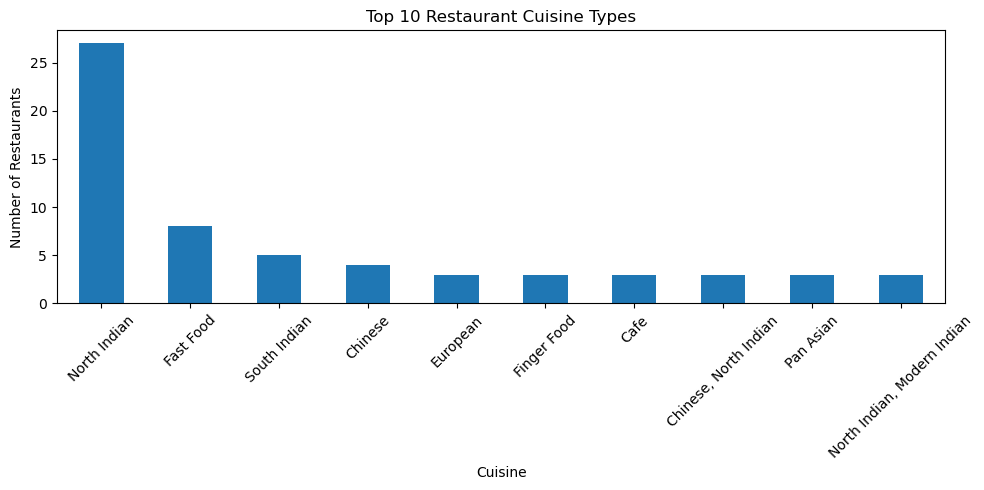

In [130]:
import matplotlib.pyplot as plt

cuisine_count.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Restaurant Cuisine Types")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

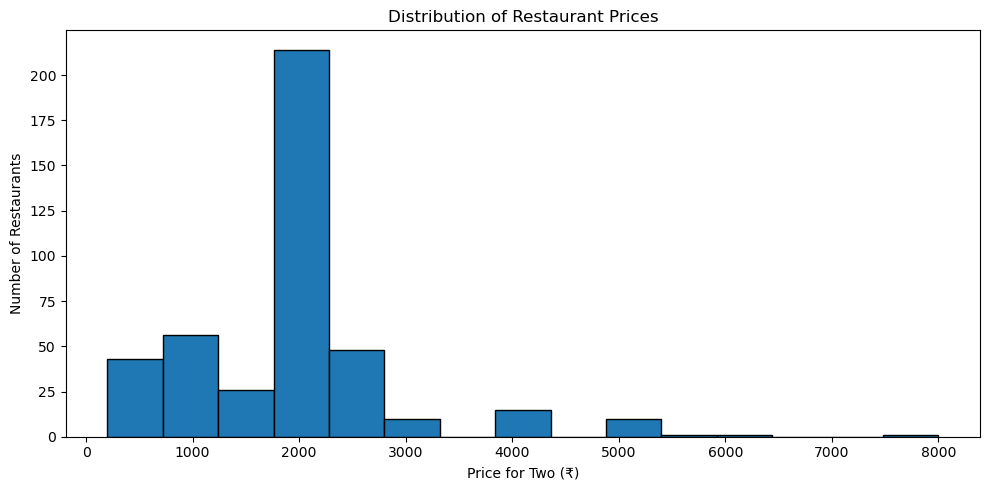

In [131]:
plt.figure(figsize=(10, 5))

plt.hist(df["Price_for_Two"], bins=15, edgecolor="black")

plt.title("Distribution of Restaurant Prices")
plt.xlabel("Price for Two (₹)")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

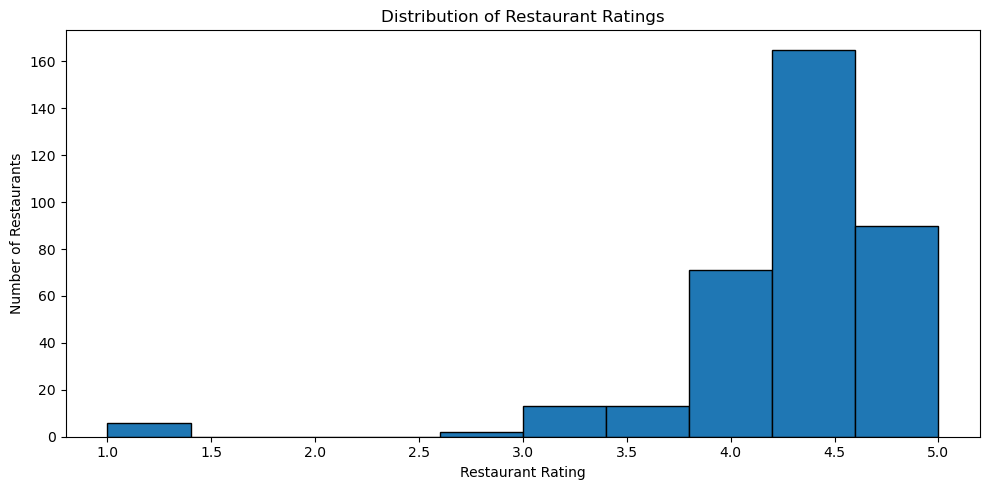

In [132]:
plt.figure(figsize=(10, 5))

plt.hist(df["Rating"].dropna(), bins=10, edgecolor="black")

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

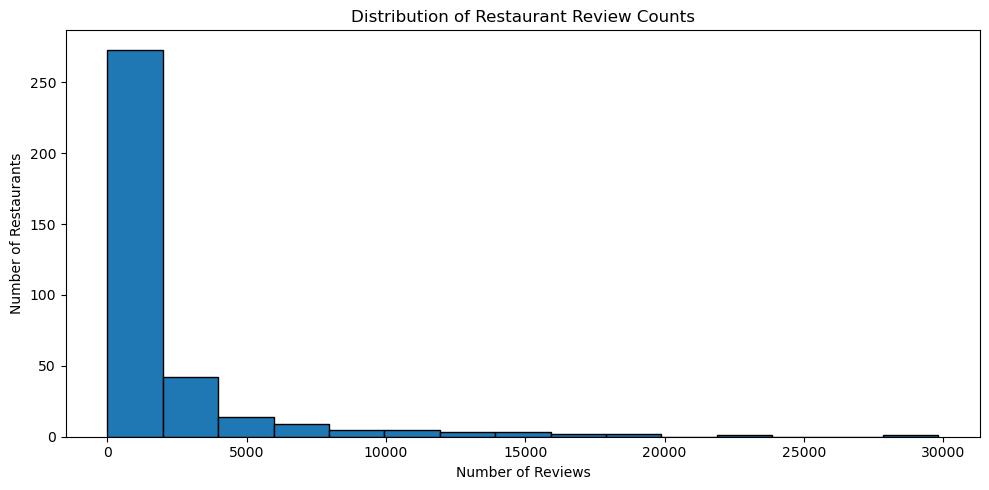

In [133]:
plt.figure(figsize=(10, 5))

plt.hist(df["Review_Count"].dropna(), bins=15, edgecolor="black")

plt.title("Distribution of Restaurant Review Counts")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

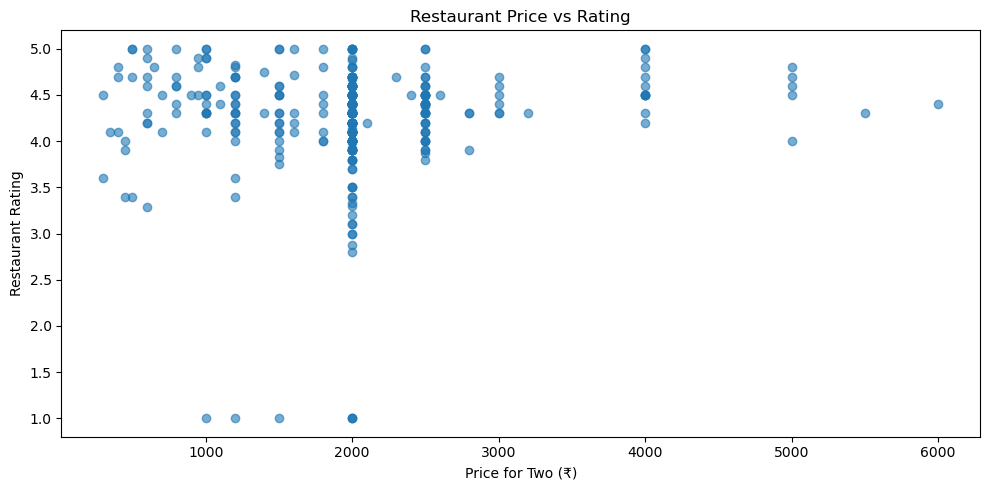

In [134]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Price_for_Two"],
    df["Rating"],
    alpha=0.6
)

plt.title("Restaurant Price vs Rating")
plt.xlabel("Price for Two (₹)")
plt.ylabel("Restaurant Rating")

plt.tight_layout()
plt.show()

In [135]:
avg_price = df.groupby("Cuisine")["Price_for_Two"].mean()

avg_price = avg_price.sort_values(ascending=False).head(10)

print(avg_price)

Cuisine
North Indian, Afghani, North West Frontier                                    5500.0
Asian, Japanese, Pan Asian, Chinese                                           5000.0
Seafood, Cocktail Menu, Global Cuisine                                        5000.0
Pan Asian, Asian, Continental                                                 5000.0
Desserts, Italian, Pizza, Sandwiches, Salad                                   5000.0
South Indian, Asian, Continental, Chinese, European, North Indian, Seafood    5000.0
Sushi, Thai, Asian                                                            5000.0
Turkish                                                                       5000.0
Desserts, Thai, Salad, Cantonese                                              5000.0
Mediterranean, Turkish, Barbeque                                              4000.0
Name: Price_for_Two, dtype: float64


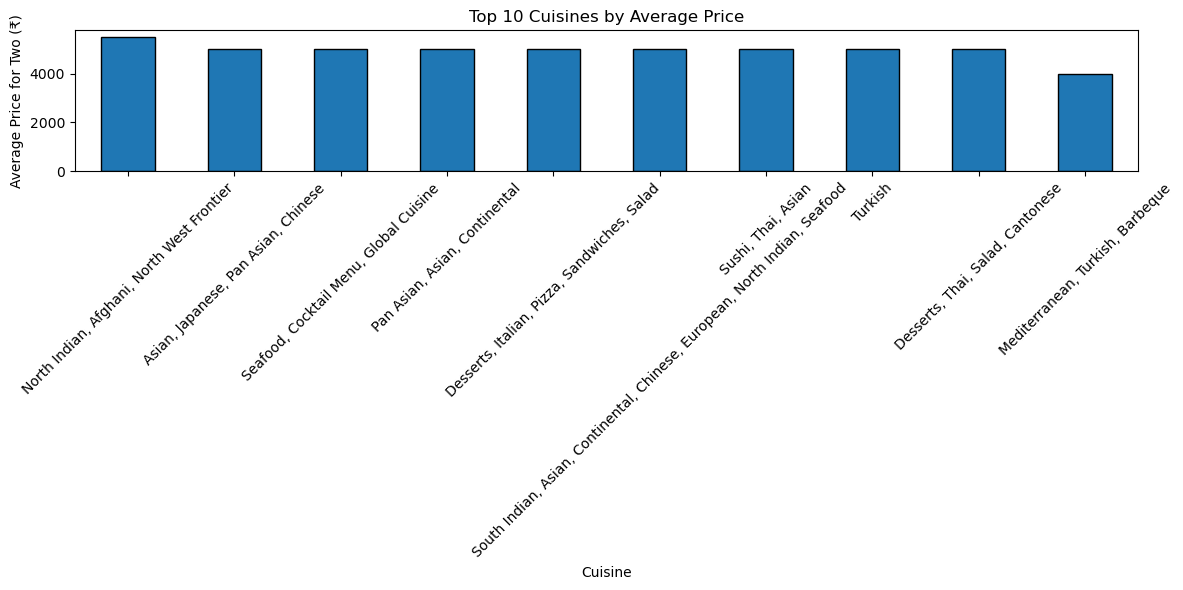

In [136]:
plt.figure(figsize=(12, 6))

avg_price.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Cuisines by Average Price")
plt.xlabel("Cuisine")
plt.ylabel("Average Price for Two (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

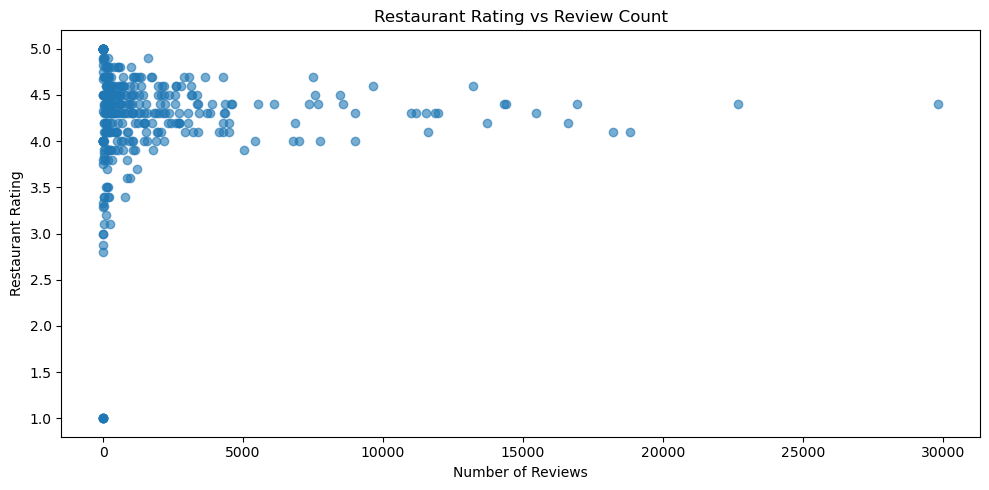

In [137]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["Review_Count"],
    df["Rating"],
    alpha=0.6
)

plt.title("Restaurant Rating vs Review Count")
plt.xlabel("Number of Reviews")
plt.ylabel("Restaurant Rating")

plt.tight_layout()
plt.show()

In [138]:
location_count = df["Location"].value_counts().head(10)

print(location_count)

Location
Ashok Nagar           26
Whitefield            23
Brigade Road          19
Church Street         19
Koramangala           16
Indiranagar           16
Shivajinagar          12
Vittal Mallya Road    12
JP Nagar              12
Residency Road        12
Name: count, dtype: int64


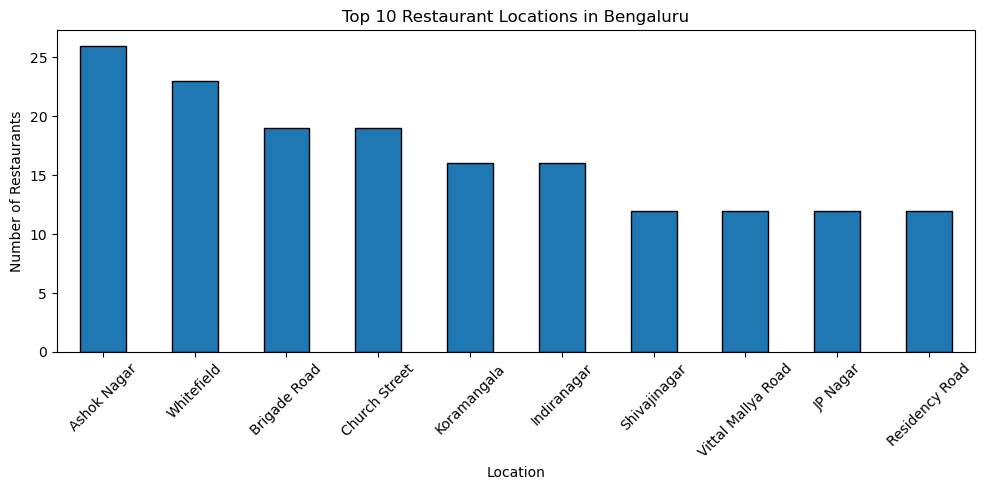

In [139]:
plt.figure(figsize=(10, 5))

location_count.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Restaurant Locations in Bengaluru")
plt.xlabel("Location")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [140]:
correlation = df[
    ["Price_for_Two", "Rating", "Review_Count"]
].corr()

print(correlation)

               Price_for_Two    Rating  Review_Count
Price_for_Two       1.000000  0.072937     -0.009301
Rating              0.072937  1.000000      0.042128
Review_Count       -0.009301  0.042128      1.000000


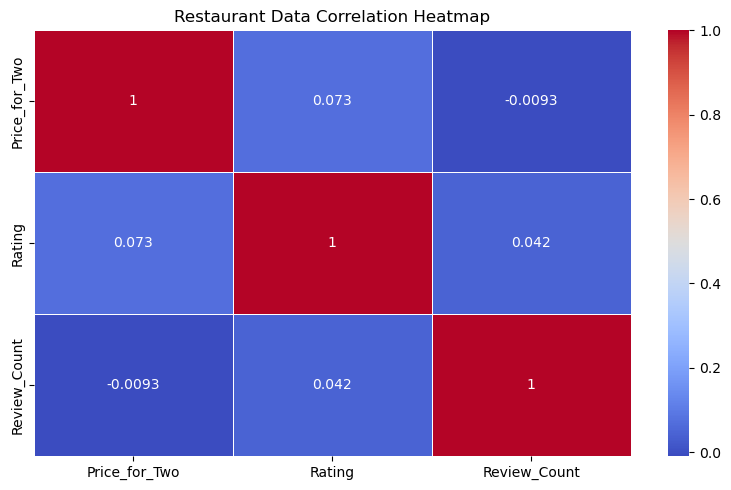

In [141]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Restaurant Data Correlation Heatmap")
plt.tight_layout()
plt.show()

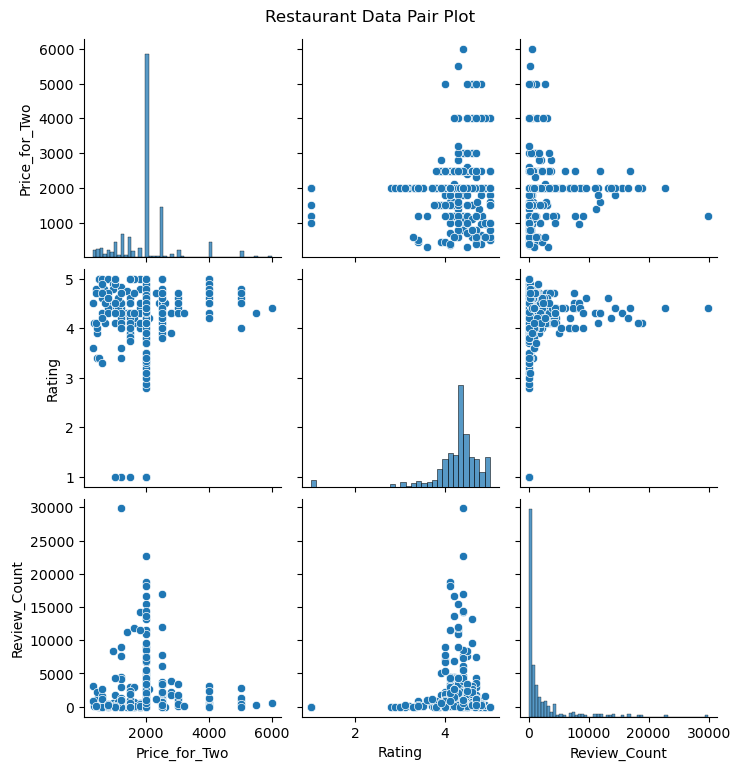

In [142]:
sns.pairplot(
    df[["Price_for_Two", "Rating", "Review_Count"]].dropna()
)

plt.suptitle("Restaurant Data Pair Plot", y=1.02)
plt.show()

In [143]:
print("Total Restaurants:", len(df))

print("Average Price for Two:",
      round(df["Price_for_Two"].mean(), 2))

print("Average Rating:",
      round(df["Rating"].mean(), 2))

print("Highest Price:",
      df["Price_for_Two"].max())

print("Lowest Price:",
      df["Price_for_Two"].min())

print("Highest Rating:",
      df["Rating"].max())

print("Total Reviews:",
      df["Review_Count"].sum())

Total Restaurants: 425
Average Price for Two: 1942.35
Average Rating: 4.27
Highest Price: 8000
Lowest Price: 200
Highest Rating: 5.0
Total Reviews: 675738.0


In [152]:
from IPython.display import display, HTML

display(HTML(
    '<a href="https://www.eazydiner.com/bengaluru/restaurants" target="_blank">'
    'Click here to open EazyDiner Bengaluru Restaurants</a>'
))